## 1. Hugging Face Login

This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

if not torch.cuda.is_available():
    print("WARNING: GPU is not available. Kaggle free-tier GPU is strongly recommended for the full Phase-1 run.")
else:
    torch.set_float32_matmul_precision("high")

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

This keeps the starter notebook's configuration flow. The values below are chosen to satisfy the Phase-1 constraints while remaining practical on Kaggle free-tier GPU resources.

In [ ]:
import os
import random
import json
import time
import math
import zipfile

ARCH_NAME = "A_GPT_MHA_LearnedPos"
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

DATA_SOURCES = {
    "supreme_court": {"file": "Phase_1_Pretraining/Train/train_supreme_court.json", "train_tokens": 100_000_000},
    "acts":          {"file": "Phase_1_Pretraining/Train/train_acts.json",          "train_tokens": 40_000_000},
    "high_courts":   {"file": "Phase_1_Pretraining/Train/train_high_courts.json",   "train_tokens": 60_000_000},
    "tribunals":     {"file": "Phase_1_Pretraining/Train/train_tribunals.json",     "train_tokens": 20_000_000},
}
TRAIN_TOKENS = sum(x["train_tokens"] for x in DATA_SOURCES.values())
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 1
SEED = 42
MODEL_CONTEXT_LENGTH = 2048
DROPOUT = 0.10
BPE_VOCAB_SIZE = 8192
BPE_TRAIN_WORDS = 300_000

TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95

OUTPUT_DIR = os.path.join("/kaggle/working/cs781_phase1", ARCH_NAME)
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-model-final")
COMMON_DIR = os.path.join("/kaggle/working/cs781_phase1", "common")
TOKENIZER_DIR = os.path.join(COMMON_DIR, "bpe_tokenizer_" + ARCH_NAME)
TOKEN_CACHE_DIR = os.path.join(COMMON_DIR, "token_cache_" + ARCH_NAME)
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
BEST_CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "best_model.pt")
TRAIN_CACHE_PATH = os.path.join(TOKEN_CACHE_DIR, "train_tokens.bin")
VAL_CACHE_PATH = os.path.join(TOKEN_CACHE_DIR, "val_tokens.bin")
CACHE_META_PATH = os.path.join(TOKEN_CACHE_DIR, "metadata.json")

PER_DEVICE_TRAIN_BATCH_SIZE = 2
PER_DEVICE_EVAL_BATCH_SIZE = 2
GRADIENT_ACCUMULATION_STEPS = 8
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1
WARMUP_STEPS = 500
LOGGING_STEPS = 100
EVAL_STEPS = 1000
MAX_EVAL_BATCHES = 50
MAX_GRAD_NORM = 1.0
NUM_WORKERS = 2
GENERATION_BATCH_SIZE = 1

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(COMMON_DIR, exist_ok=True)
os.makedirs(TOKEN_CACHE_DIR, exist_ok=True)

print("Configuration loaded.")
print("Architecture:", ARCH_NAME)
print("Training budgets:", {name: f"{spec['train_tokens']:,}" for name, spec in DATA_SOURCES.items()})
print(f"Total train tokens: {TRAIN_TOKENS:,}")
print(f"Validation tokens: {VAL_TOKENS:,}")

N_EMBD = 768
N_LAYER = 8
N_HEAD = 8
N_FF = 3072

CONFIG = {
    "architecture": ARCH_NAME,
    "type": "decoder-only",
    "d_model": N_EMBD,
    "n_layer": N_LAYER,
    "n_head": N_HEAD,
    "d_ff": N_FF,
    "context_length": MODEL_CONTEXT_LENGTH,
}

Configuration loaded.
Architecture: A_GPT_MHA_LearnedPos
Training budgets: {'supreme_court': '100,000,000', 'acts': '40,000,000', 'high_courts': '60,000,000', 'tribunals': '20,000,000'}
Total train tokens: 220,000,000
Validation tokens: 5,000,000


## 4. Load Tokenizer

The supplied byte-level BPE tokenizer is used here; it is trained from the provided legal corpus and never uses a pretrained tokenizer.

In [4]:
from collections import Counter
SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]

class BPETokenizer:
    """
    BPE tokenizer based directly on the supplied course-assignment tokenizer.

    The byte-level representation and merge-learning logic are retained. Two small fixes are
    included so the notebook is executable at scale: the byte-token initialization bug is
    removed, and decoding distinguishes raw byte tokens from merged numeric tokens.
    """
    def __init__(self, vocab_size):
        self.vocab_size = int(vocab_size)
        self.token_to_id = {tok: i for i, tok in enumerate(SPECIAL_TOKENS)}
        self.id_to_token = {i: tok for i, tok in enumerate(SPECIAL_TOKENS)}
        self.merges = []
        self.merge_ranks = {}
        self._merge_map = {}
        self._byte_tokens = {str(i) for i in range(256)}
        self._word_cache = {}
        self.encode_word_cache_limit = 100_000

    def train(self, text):
        words = Counter(text.split())
        corpus = []
        for word, freq in words.items():
            tokens = [str(b) for b in word.encode("utf-8")]
            tokens.append("</w>")
            corpus.append([tokens, freq])

        for b in range(256):
            token = str(b)
            if token not in self.token_to_id:
                idx = len(self.token_to_id)
                self.token_to_id[token] = idx
                self.id_to_token[idx] = token

        if "</w>" not in self.token_to_id:
            idx = len(self.token_to_id)
            self.token_to_id["</w>"] = idx
            self.id_to_token[idx] = "</w>"

        while len(self.token_to_id) < self.vocab_size:
            pair_counts = Counter()
            for tokens, freq in corpus:
                for i in range(len(tokens) - 1):
                    if tokens[i] == "</w>" or tokens[i + 1] == "</w>":
                        continue
                    pair_counts[(tokens[i], tokens[i + 1])] += freq
            if not pair_counts:
                break
            max_count = max(pair_counts.values())
            if max_count <= 1:
                break
            best_pair = min(pair for pair, count in pair_counts.items() if count == max_count)
            a, b = best_pair
            merged = a + b
            if merged in self.token_to_id:
                break
            self.merges.append(best_pair)
            idx = len(self.token_to_id)
            self.token_to_id[merged] = idx
            self.id_to_token[idx] = merged

            new_corpus = []
            for tokens, freq in corpus:
                new_tokens = []
                i = 0
                while i < len(tokens):
                    if (
                        i + 1 < len(tokens)
                        and tokens[i] != "</w>"
                        and tokens[i + 1] != "</w>"
                        and tokens[i] == a
                        and tokens[i + 1] == b
                    ):
                        new_tokens.append(merged)
                        i += 2
                    else:
                        new_tokens.append(tokens[i])
                        i += 1
                new_corpus.append([new_tokens, freq])
            corpus = new_corpus

        self._rebuild_merge_maps()
        self._word_cache.clear()
        return len(self.token_to_id)

    def _rebuild_merge_maps(self):
        self.merge_ranks = {pair: i for i, pair in enumerate(self.merges)}
        self._merge_map = {a + b: (a, b) for a, b in self.merges}
        self._word_cache.clear()

    def _encode_word(self, word):
        if word in self._word_cache:
            return self._word_cache[word]
        tokens = [str(b) for b in word.encode("utf-8")]
        tokens.append("</w>")

        while len(tokens) > 1:
            best_rank = None
            best_index = -1
            for i in range(len(tokens) - 1):
                rank = self.merge_ranks.get((tokens[i], tokens[i + 1]))
                if rank is not None and (best_rank is None or rank < best_rank):
                    best_rank = rank
                    best_index = i
            if best_index < 0:
                break
            merged = tokens[best_index] + tokens[best_index + 1]
            tokens[best_index:best_index + 2] = [merged]

        ids = tuple(self.token_to_id.get(token, self.token_to_id["<unk>"]) for token in tokens)
        if len(self._word_cache) < self.encode_word_cache_limit:
            self._word_cache[word] = ids
        return ids

    def encode(self, text):
        ids = []
        for word in text.split():
            ids.extend(self._encode_word(word))
        return ids

    def decode(self, ids):
        words = []
        current = bytearray()
        for idx in ids:
            if int(idx) not in self.id_to_token:
                continue
            token = self.id_to_token[int(idx)]
            if token in SPECIAL_TOKENS:
                continue
            if token == "</w>":
                if current:
                    words.append(current.decode("utf-8", errors="replace"))
                    current = bytearray()
                continue
            current.extend(self._get_bytes(token))
        if current:
            words.append(current.decode("utf-8", errors="replace"))
        return " ".join(words)

    def _get_bytes(self, token):
        if token in self._merge_map:
            a, b = self._merge_map[token]
            return self._get_bytes(a) + self._get_bytes(b)
        if token in self._byte_tokens:
            return bytes([int(token)])
        return b""

    def get_vocab_size(self):
        return len(self.token_to_id)

    def save_pretrained(self, directory):
        os.makedirs(directory, exist_ok=True)
        data = {
            "vocab_size_requested": self.vocab_size,
            "token_to_id": self.token_to_id,
            "merges": self.merges,
        }
        with open(os.path.join(directory, "tokenizer.json"), "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)

    @classmethod
    def from_pretrained(cls, directory):
        with open(os.path.join(directory, "tokenizer.json"), "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls(data["vocab_size_requested"])
        tok.token_to_id = {str(k): int(v) for k, v in data["token_to_id"].items()}
        tok.id_to_token = {int(v): str(k) for k, v in tok.token_to_id.items()}
        tok.merges = [tuple(pair) for pair in data["merges"]]
        tok._rebuild_merge_maps()
        return tok

if os.path.exists(os.path.join(TOKENIZER_DIR, "tokenizer.json")):
    tokenizer = BPETokenizer.from_pretrained(TOKENIZER_DIR)
    VOCAB_SIZE = tokenizer.get_vocab_size()
    print("Loaded existing BPE tokenizer from:", TOKENIZER_DIR)
    print("Vocabulary size:", VOCAB_SIZE)
else:
    tokenizer = None
    VOCAB_SIZE = None
    print("No cached BPE tokenizer found; it will be trained from the provided legal corpus in Section 6.")

No cached BPE tokenizer found; it will be trained from the provided legal corpus in Section 6.


## 5. Download Training Data From Hugging Face

In [5]:
from huggingface_hub import hf_hub_download

source_paths = {}
for name, spec in DATA_SOURCES.items():
    path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=spec["file"],
        repo_type="dataset",
        token=HF_TOKEN,
    )
    source_paths[name] = path
    print(f"{name}: {path}")
print("Downloaded", len(source_paths), "training sources.")

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

supreme_court: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

acts: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_acts.json


Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

high_courts: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_high_courts.json


Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

tribunals: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_tribunals.json
Downloaded 4 training sources.


## 6. Create Train and Validation Tokens Set

In [6]:
import os
import json
import time
import math
import random
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
TOKEN_DTYPE = np.uint16

def stream_json_array(path, chunk_size=4 * 1024 * 1024):
    """Read a large JSON array one record at a time; never json.load the full file."""
    decoder = json.JSONDecoder()
    buffer = ""
    started = False
    with open(path, "r", encoding="utf-8") as f:
        while True:
            chunk = f.read(chunk_size)
            if chunk:
                buffer += chunk
            elif not buffer:
                break
            pos = 0
            while True:
                while pos < len(buffer) and buffer[pos].isspace():
                    pos += 1
                if not started:
                    if pos >= len(buffer):
                        break
                    if buffer[pos] != "[":
                        raise ValueError("Training file must be a top-level JSON array.")
                    started = True
                    pos += 1
                while pos < len(buffer) and buffer[pos].isspace():
                    pos += 1
                if pos >= len(buffer):
                    break
                if buffer[pos] == "]":
                    return
                if buffer[pos] == ",":
                    pos += 1
                    continue
                try:
                    obj, end = decoder.raw_decode(buffer, pos)
                except json.JSONDecodeError:
                    break
                yield obj
                pos = end
            buffer = buffer[pos:]

def record_text(record):
    text = record.get("text", "") if isinstance(record, dict) else ""
    return text if isinstance(text, str) else str(text)

def collect_tokenizer_text(source_paths, source_budgets, max_words):
    """Use a proportional sample from all four sources for BPE training."""
    total = sum(source_budgets.values())
    parts = []
    for name, path in source_paths.items():
        target = max(1, int(max_words * source_budgets[name] / total))
        words = []
        for record in stream_json_array(path):
            text = record_text(record)
            if text:
                words.extend(text.split())
            if len(words) >= target:
                break
        parts.append(" ".join(words[:target]))
        print(f"Tokenizer sample - {name}: {len(words[:target]):,} words")
    return " ".join(parts)

def load_or_build_token_cache(source_paths, source_budgets, tokenizer, val_total, train_path, val_path, meta_path):
    """Tokenize each source once and write fixed-size uint16 caches directly to disk."""
    expected = {"budgets": source_budgets, "val_total": val_total, "vocab": tokenizer.get_vocab_size()}
    if os.path.exists(meta_path) and os.path.exists(train_path) and os.path.exists(val_path):
        try:
            with open(meta_path, "r", encoding="utf-8") as f:
                meta = json.load(f)
            if all(meta.get(k) == v for k, v in expected.items()):
                print("Using existing token cache.")
                return meta["train_tokens"], meta["val_tokens"]
        except Exception:
            pass

    train_target = sum(source_budgets.values()) + 1
    val_budgets = {k: max(1, int(val_total * v / sum(source_budgets.values()))) for k, v in source_budgets.items()}
    val_target = sum(val_budgets.values()) + 1
    train_mm = np.memmap(train_path, dtype=TOKEN_DTYPE, mode="w+", shape=(train_target,))
    val_mm = np.memmap(val_path, dtype=TOKEN_DTYPE, mode="w+", shape=(val_target,))
    train_pos = val_pos = 0

    for source_index, (name, path) in enumerate(source_paths.items()):
        train_limit = source_budgets[name]
        val_limit = val_budgets[name]
        source_train = source_val = 0
        rng = random.Random(SEED + source_index)
        for record in stream_json_array(path):
            text = record_text(record)
            if len(text) < 20:
                continue
            ids = tokenizer.encode(text)
            if not ids:
                continue
            if rng.random() < 0.05 and source_val < val_limit:
                take = min(len(ids), val_limit - source_val)
                val_mm[val_pos:val_pos + take] = ids[:take]
                val_pos += take
                source_val += take
            elif source_train < train_limit:
                take = min(len(ids), train_limit - source_train)
                train_mm[train_pos:train_pos + take] = ids[:take]
                train_pos += take
                source_train += take
            if source_train >= train_limit and source_val >= val_limit:
                break
        print(f"{name}: train {source_train:,} | val {source_val:,}")

    train_mm.flush(); val_mm.flush()
    del train_mm, val_mm
    if train_pos <= TRAIN_BLOCK_SIZE or val_pos <= TRAIN_BLOCK_SIZE:
        raise RuntimeError("Not enough tokenized data for one training block.")
    meta = {**expected, "train_tokens": train_pos, "val_tokens": val_pos}
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)
    print(f"Train tokens: {train_pos:,}")
    print(f"Validation tokens: {val_pos:,}")
    return train_pos, val_pos

def build_dataloader(dataset, batch_size, shuffle, num_workers):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers,
        pin_memory=torch.cuda.is_available(), drop_last=False,
        persistent_workers=(num_workers > 0),
    )

class TokenBlockDataset(Dataset):
    def __init__(self, path, n_tokens, block_size):
        self.n_tokens = int(n_tokens)
        self.block_size = int(block_size)
        self.tokens = np.memmap(path, dtype=TOKEN_DTYPE, mode="r", shape=(self.n_tokens,))
        self.n_blocks = max(0, (self.n_tokens - 1) // self.block_size)
    def __len__(self):
        return self.n_blocks
    def __getitem__(self, idx):
        start = idx * self.block_size
        a = np.array(self.tokens[start:start + self.block_size + 1], dtype=np.int64)
        return {"input_ids": torch.from_numpy(a[:-1]), "labels": torch.from_numpy(a[1:])}

def build_optimizer(model, learning_rate, weight_decay):
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if param.ndim >= 2 and "norm" not in name.lower():
            decay.append(param)
        else:
            no_decay.append(param)
    return torch.optim.AdamW(
        [
            {"params": decay, "weight_decay": weight_decay},
            {"params": no_decay, "weight_decay": 0.0},
        ],
        lr=learning_rate,
        betas=(0.9, 0.95),
        eps=1e-8,
    )

def lr_for_step(step, total_steps, base_lr, warmup_steps, min_lr_ratio=0.1):
    if step <= warmup_steps:
        return base_lr * step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    cosine = 0.5 * (1.0 + math.cos(math.pi * min(1.0, max(0.0, progress))))
    return base_lr * (min_lr_ratio + (1.0 - min_lr_ratio) * cosine)

def set_lr(optimizer, lr):
    for group in optimizer.param_groups:
        group["lr"] = lr

@torch.no_grad()
def evaluate_loss(model, loader, model_kind, max_batches):
    model.eval()
    total_loss = 0.0
    batches = 0
    for batch in loader:
        if batches >= max_batches:
            break
        if model_kind == "encoder_decoder":
            src = batch["input_ids"].to(DEVICE, non_blocking=True)
            dec = batch["decoder_input_ids"].to(DEVICE, non_blocking=True)
            labels = batch["labels"].to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(src, dec)
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))
        else:
            x = batch["input_ids"].to(DEVICE, non_blocking=True)
            labels = batch["labels"].to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(x)
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))
        total_loss += float(loss.item())
        batches += 1
    if batches == 0:
        return float("inf")
    return total_loss / batches

def save_checkpoint(path, model, config_dict, step, eval_loss):
    state = {
        "model": model.state_dict(),
        "config": config_dict,
        "step": int(step),
        "eval_loss": float(eval_loss),
    }
    torch.save(state, path)

def train_loop(model, train_loader, val_loader, config_dict, model_kind):
    model.to(DEVICE)
    optimizer = build_optimizer(model, LEARNING_RATE, WEIGHT_DECAY)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    updates_per_epoch = math.ceil(len(train_loader) / GRADIENT_ACCUMULATION_STEPS)
    total_steps = updates_per_epoch * EPOCHS
    global_step = 0
    best_eval = float("inf")
    start_time = time.time()

    train_history = []
    eval_history = []
    model.train()
    optimizer.zero_grad(set_to_none=True)

    for epoch in range(EPOCHS):
        for micro_step, batch in enumerate(train_loader):
            if model_kind == "encoder_decoder":
                src = batch["input_ids"].to(DEVICE, non_blocking=True)
                dec = batch["decoder_input_ids"].to(DEVICE, non_blocking=True)
                labels = batch["labels"].to(DEVICE, non_blocking=True)
                with torch.cuda.amp.autocast(enabled=USE_AMP):
                    logits = model(src, dec)
                    raw_loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))
            else:
                x = batch["input_ids"].to(DEVICE, non_blocking=True)
                labels = batch["labels"].to(DEVICE, non_blocking=True)
                with torch.cuda.amp.autocast(enabled=USE_AMP):
                    logits = model(x)
                    raw_loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))

            loss = raw_loss / GRADIENT_ACCUMULATION_STEPS
            scaler.scale(loss).backward()

            should_step = ((micro_step + 1) % GRADIENT_ACCUMULATION_STEPS == 0) or (micro_step + 1 == len(train_loader))
            if not should_step:
                continue

            global_step += 1
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            lr = lr_for_step(global_step, total_steps, LEARNING_RATE, WARMUP_STEPS)
            set_lr(optimizer, lr)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

            train_history.append((global_step, float(raw_loss.item())))

            if global_step % LOGGING_STEPS == 0 or global_step == 1:
                elapsed = max(1e-6, time.time() - start_time)
                print(
                    f"step {global_step:6d}/{total_steps:<6d} | "
                    f"train loss {raw_loss.item():.4f} | lr {lr:.3e} | "
                    f"elapsed {elapsed / 60:.1f} min"
                )

            if global_step % EVAL_STEPS == 0:
                val_loss = evaluate_loss(model, val_loader, model_kind, MAX_EVAL_BATCHES)
                eval_history.append((global_step, val_loss))
                print(f"step {global_step:6d} | validation loss {val_loss:.4f} | perplexity {math.exp(min(val_loss, 20)):.3f}")
                if val_loss < best_eval:
                    best_eval = val_loss
                    save_checkpoint(BEST_CHECKPOINT_PATH, model, config_dict, global_step, val_loss)
                model.train()

    val_loss = evaluate_loss(model, val_loader, model_kind, MAX_EVAL_BATCHES)
    eval_history.append((global_step, val_loss))
    print(f"Final validation loss: {val_loss:.4f}")
    if val_loss < best_eval or not os.path.exists(BEST_CHECKPOINT_PATH):
        best_eval = val_loss
        save_checkpoint(BEST_CHECKPOINT_PATH, model, config_dict, global_step, val_loss)

    training_time = time.time() - start_time
    used_train_tokens = len(train_loader.dataset) * TRAIN_BLOCK_SIZE
    tokens_per_second = used_train_tokens / max(1e-6, training_time)
    print(f"Training time: {training_time / 3600:.2f} hours")
    print(f"Training speed: {tokens_per_second:,.0f} tokens/sec")

    return train_history, eval_history, best_eval, global_step

def sample_top_p(logits, temperature, top_p):
    temperature = max(float(temperature), 1e-5)
    top_p = float(top_p)
    logits = logits.float() / temperature
    sorted_logits, sorted_indices = torch.sort(logits, descending=True)
    sorted_probs = torch.softmax(sorted_logits, dim=-1)
    cumulative_probs = torch.cumsum(sorted_probs, dim=-1)
    remove = cumulative_probs > top_p
    remove[..., 1:] = remove[..., :-1].clone()
    remove[..., 0] = False
    sorted_probs = sorted_probs.masked_fill(remove, 0.0)
    sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
    sampled = torch.multinomial(sorted_probs, num_samples=1)
    return sorted_indices.gather(-1, sampled).squeeze(-1)

if tokenizer is None:
    tokenizer_text = collect_tokenizer_text(
        source_paths,
        {k: v["train_tokens"] for k, v in DATA_SOURCES.items()},
        BPE_TRAIN_WORDS,
    )
    tokenizer = BPETokenizer(BPE_VOCAB_SIZE)
    tokenizer.train(tokenizer_text)
    tokenizer.save_pretrained(TOKENIZER_DIR)
    print("BPE tokenizer trained and saved.")

VOCAB_SIZE = tokenizer.get_vocab_size()
print("Vocabulary size:", VOCAB_SIZE)
if VOCAB_SIZE > 65535:
    raise RuntimeError("BPE vocabulary must stay below 65536 for uint16 token storage.")

train_tokens_count, val_tokens_count = load_or_build_token_cache(
    source_paths,
    {k: v["train_tokens"] for k, v in DATA_SOURCES.items()},
    tokenizer,
    VAL_TOKENS + 1,
    TRAIN_CACHE_PATH,
    VAL_CACHE_PATH,
    CACHE_META_PATH,
)
print(f"Train tokens: {train_tokens_count:,}")
print(f"Validation tokens: {val_tokens_count:,}")

Tokenizer sample - supreme_court: 136,363 words
Tokenizer sample - acts: 54,545 words
Tokenizer sample - high_courts: 81,818 words
Tokenizer sample - tribunals: 27,272 words
BPE tokenizer trained and saved.
Vocabulary size: 8192
supreme_court: train 100,000,000 | val 2,272,727
acts: train 40,000,000 | val 909,091
high_courts: train 60,000,000 | val 1,363,636
tribunals: train 20,000,000 | val 454,545
Train tokens: 220,000,000
Validation tokens: 4,999,999
Train tokens: 220,000,000
Validation tokens: 4,999,999


## 7. Create Token Blocks

In [7]:
print("Training block size:", TRAIN_BLOCK_SIZE)
print("Model context length:", MODEL_CONTEXT_LENGTH)

Training block size: 2048
Model context length: 2048


## 8. Create Datasets

In [8]:
def causal_mask(q_len, k_len, past_len=0, device=None):
    q_pos = torch.arange(past_len, past_len + q_len, device=device)
    k_pos = torch.arange(0, k_len, device=device)
    return k_pos.unsqueeze(0) > q_pos.unsqueeze(1)

def local_causal_mask(q_len, k_len, past_len, window_size, device=None):
    q_pos = torch.arange(past_len, past_len + q_len, device=device)
    k_pos = torch.arange(0, k_len, device=device)
    future = k_pos.unsqueeze(0) > q_pos.unsqueeze(1)
    too_old = k_pos.unsqueeze(0) < (q_pos.unsqueeze(1) - window_size + 1)
    return future | too_old

train_dataset = TokenBlockDataset(TRAIN_CACHE_PATH, train_tokens_count, TRAIN_BLOCK_SIZE)
val_dataset = TokenBlockDataset(VAL_CACHE_PATH, val_tokens_count, TRAIN_BLOCK_SIZE)

train_loader = build_dataloader(train_dataset, PER_DEVICE_TRAIN_BATCH_SIZE, True, NUM_WORKERS)
val_loader = build_dataloader(val_dataset, PER_DEVICE_EVAL_BATCH_SIZE, False, NUM_WORKERS)

print("Training sequences:", len(train_dataset))
print("Validation sequences:", len(val_dataset))

Training sequences: 107421
Validation sequences: 2441


## 9. Define The Model

Architecture A — Decoder-only Transformer with MHA and learned positions

Substantially different baseline: standard multi-head causal self-attention, learned positional embeddings, LayerNorm, GELU.

All model parameters below are randomly initialized; no pretrained language model or pretrained model weights are loaded.

In [9]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def assert_parameter_range(model):
    params = count_parameters(model)
    print(f"Model size: {params / 1e6:.2f}M parameters")
    if not (50_000_000 <= params <= 300_000_000):
        raise RuntimeError(
            f"Phase-1 rule violation: model has {params:,} parameters; required range is 50M to 300M."
        )

def load_best_state(model):
    checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location="cpu")
    model.load_state_dict(checkpoint["model"], strict=True)
    print(f"Loaded best checkpoint from step {checkpoint['step']} with validation loss {checkpoint['eval_loss']:.4f}")
    return checkpoint

@torch.no_grad()
def generate_continuation_decoder(prompt, model, tokenizer, target_words=128):
    model.eval()
    prompt_ids = tokenizer.encode(prompt)
    if not prompt_ids:
        prompt_ids = [tokenizer.token_to_id["<s>"]]
    max_prompt = MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS
    if len(prompt_ids) > max_prompt:
        prompt_ids = prompt_ids[:max_prompt]

    input_ids = torch.tensor([prompt_ids], device=DEVICE, dtype=torch.long)
    logits, past = model(input_ids, use_cache=True)
    generated = []
    for _ in range(MAX_GENERATION_TOKENS):
        next_id = int(sample_top_p(logits[:, -1, :], TEMPERATURE, TOP_P).item())
        generated.append(next_id)
        if next_id == tokenizer.token_to_id["</s>"]:
            break
        if len(prompt_ids) + len(generated) >= MODEL_CONTEXT_LENGTH:
            break
        next_tensor = torch.tensor([[next_id]], device=DEVICE, dtype=torch.long)
        logits, past = model(next_tensor, past_key_values=past, use_cache=True)

    text = tokenizer.decode(generated)
    return " ".join(text.split()[:target_words])

class CausalSelfAttentionMHA(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=True)
        self.out = nn.Linear(d_model, d_model, bias=True)
        self.dropout = dropout

    def forward(self, x, past_key_value=None, use_cache=False):
        b, t, c = x.shape
        qkv = self.qkv(x)
        q, k, v = qkv.chunk(3, dim=-1)
        q = q.view(b, t, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(b, t, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(b, t, self.n_heads, self.head_dim).transpose(1, 2)

        past_len = 0
        if past_key_value is not None:
            pk, pv = past_key_value
            past_len = pk.size(2)
            k = torch.cat([pk, k], dim=2)
            v = torch.cat([pv, v], dim=2)

        if past_len == 0:
            y = F.scaled_dot_product_attention(
                q, k, v,
                attn_mask=None,
                dropout_p=self.dropout if self.training else 0.0,
                is_causal=True,
            )
        else:
            mask = causal_mask(t, k.size(2), past_len, x.device)
            y = F.scaled_dot_product_attention(
                q, k, v,
                attn_mask=(~mask).view(1, 1, t, k.size(2)),
                dropout_p=self.dropout if self.training else 0.0,
                is_causal=False,
            )

        y = y.transpose(1, 2).contiguous().view(b, t, c)
        y = self.out(y)
        present = (k, v) if use_cache else None
        return y, present

class EncoderBlockA(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1 = nn.LayerNorm(N_EMBD)
        self.attn = CausalSelfAttentionMHA(N_EMBD, N_HEAD, DROPOUT)
        self.ln2 = nn.LayerNorm(N_EMBD)
        self.fc1 = nn.Linear(N_EMBD, N_FF)
        self.fc2 = nn.Linear(N_FF, N_EMBD)
        self.dropout = nn.Dropout(DROPOUT)

    def forward(self, x, past_key_value=None, use_cache=False):
        a, present = self.attn(self.ln1(x), past_key_value=past_key_value, use_cache=use_cache)
        x = x + self.dropout(a)
        m = self.fc2(F.gelu(self.fc1(self.ln2(x))))
        x = x + self.dropout(m)
        return x, present

class DecoderOnlyA(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(VOCAB_SIZE, N_EMBD)
        self.position_embedding = nn.Embedding(MODEL_CONTEXT_LENGTH, N_EMBD)
        self.blocks = nn.ModuleList([EncoderBlockA() for _ in range(N_LAYER)])
        self.ln_f = nn.LayerNorm(N_EMBD)
        self.config = CONFIG
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, past_key_values=None, use_cache=False):
        b, t = input_ids.shape
        past_len = 0 if past_key_values is None else past_key_values[0][0].size(2)
        if past_len + t > MODEL_CONTEXT_LENGTH:
            raise ValueError("Sequence exceeds MODEL_CONTEXT_LENGTH.")
        positions = torch.arange(past_len, past_len + t, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)[None, :, :]
        presents = []
        for i, block in enumerate(self.blocks):
            past = None if past_key_values is None else past_key_values[i]
            x, present = block(x, past_key_value=past, use_cache=use_cache)
            if use_cache:
                presents.append(present)
        x = self.ln_f(x)
        logits = F.linear(x, self.token_embedding.weight)
        if use_cache:
            return logits, tuple(presents)
        return logits

model = DecoderOnlyA().to(DEVICE)
assert_parameter_range(model)
print("Model configuration:")
print(json.dumps(CONFIG, indent=2))

Model size: 64.57M parameters
Model configuration:
{
  "architecture": "A_GPT_MHA_LearnedPos",
  "type": "decoder-only",
  "d_model": 768,
  "n_layer": 8,
  "n_head": 8,
  "d_ff": 3072,
  "context_length": 2048
}


## 10. Training Arguments

In [10]:
print("The model is trained from scratch with a custom PyTorch loop.")
print(f"Micro-batch size: {PER_DEVICE_TRAIN_BATCH_SIZE}")
print(f"Gradient accumulation: {GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective batch size: {PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Warmup steps: {WARMUP_STEPS}")
print(f"FP16 AMP: {USE_AMP}")

The model is trained from scratch with a custom PyTorch loop.
Micro-batch size: 2
Gradient accumulation: 8
Effective batch size: 16
Learning rate: 0.0003
Weight decay: 0.1
Warmup steps: 500
FP16 AMP: True


## 11. Training

In [11]:
model.train()
train_history, eval_history, best_eval_loss, best_step = train_loop(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    config_dict=CONFIG,
    model_kind="decoder_only"
)
print("Best validation loss:", best_eval_loss)
print("Best checkpoint step:", best_step)

/tmp/ipykernel_23/2440225343.py:234: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_23/2440225343.py:259: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


step      1/6714   | train loss 9.0706 | lr 6.000e-07 | elapsed 0.0 min
step    100/6714   | train loss 3.9636 | lr 6.000e-05 | elapsed 2.1 min
step    200/6714   | train loss 3.5476 | lr 1.200e-04 | elapsed 4.5 min
step    300/6714   | train loss 3.6979 | lr 1.800e-04 | elapsed 6.9 min
step    400/6714   | train loss 3.9298 | lr 2.400e-04 | elapsed 9.3 min
step    500/6714   | train loss 3.3555 | lr 3.000e-04 | elapsed 11.8 min
step    600/6714   | train loss 3.4941 | lr 2.998e-04 | elapsed 14.2 min
step    700/6714   | train loss 3.4335 | lr 2.993e-04 | elapsed 16.7 min
step    800/6714   | train loss 2.9863 | lr 2.985e-04 | elapsed 19.1 min
step    900/6714   | train loss 2.4755 | lr 2.972e-04 | elapsed 21.6 min
step   1000/6714   | train loss 2.9855 | lr 2.957e-04 | elapsed 24.0 min


/tmp/ipykernel_23/2440225343.py:211: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


step   1000 | validation loss 3.0423 | perplexity 20.954
step   1100/6714   | train loss 2.9687 | lr 2.938e-04 | elapsed 26.5 min
step   1200/6714   | train loss 2.8431 | lr 2.916e-04 | elapsed 28.9 min
step   1300/6714   | train loss 2.4627 | lr 2.891e-04 | elapsed 31.4 min
step   1400/6714   | train loss 2.6846 | lr 2.863e-04 | elapsed 33.8 min
step   1500/6714   | train loss 1.8854 | lr 2.831e-04 | elapsed 36.3 min
step   1600/6714   | train loss 2.9463 | lr 2.797e-04 | elapsed 38.7 min
step   1700/6714   | train loss 2.5045 | lr 2.759e-04 | elapsed 41.2 min
step   1800/6714   | train loss 2.1835 | lr 2.719e-04 | elapsed 43.6 min
step   1900/6714   | train loss 2.0101 | lr 2.676e-04 | elapsed 46.1 min
step   2000/6714   | train loss 2.3877 | lr 2.630e-04 | elapsed 48.5 min
step   2000 | validation loss 2.3746 | perplexity 10.747
step   2100/6714   | train loss 2.5281 | lr 2.582e-04 | elapsed 51.0 min
step   2200/6714   | train loss 1.8426 | lr 2.531e-04 | elapsed 53.4 min
step   230

## 12. Perplexity

In [12]:
perplexity = math.exp(min(best_eval_loss, 20.0))
print(f"Validation loss: {best_eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

Validation loss: 1.783959
Validation perplexity: 5.9534


## 13. Plot Training and Validation Loss

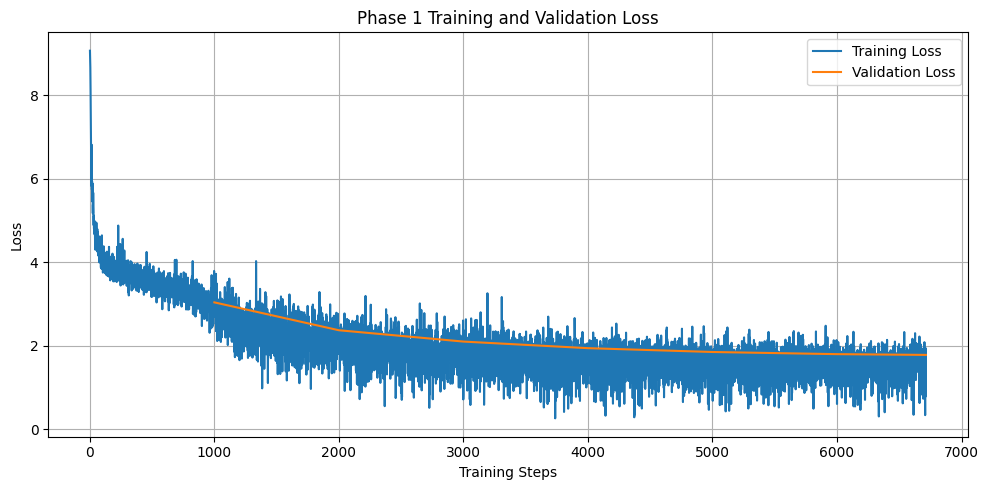

Loss plot saved to:
/kaggle/working/cs781_phase1/A_GPT_MHA_LearnedPos/training_validation_loss.png


In [13]:
import matplotlib.pyplot as plt

train_steps = [s for s, _ in train_history]
train_loss_values = [v for _, v in train_history]
eval_steps = [s for s, _ in eval_history]
eval_loss_values = [v for _, v in eval_history]

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss_values, label="Training Loss")
plt.plot(eval_steps, eval_loss_values, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [14]:
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
best_checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location="cpu")
model.load_state_dict(best_checkpoint["model"], strict=True)

torch.save(
    {
        "model": model.state_dict(),
        "config": CONFIG,
        "tokenizer_vocab_size": tokenizer.get_vocab_size(),
        "best_eval_loss": float(best_checkpoint["eval_loss"]),
        "best_step": int(best_checkpoint["step"]),
    },
    os.path.join(MODEL_OUTPUT_DIR, "model.pt"),
)
with open(os.path.join(MODEL_OUTPUT_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

with open(os.path.join(MODEL_OUTPUT_DIR, "training_history.json"), "w", encoding="utf-8") as f:
    json.dump(
        {
            "train_history": train_history,
            "eval_history": eval_history,
            "best_eval_loss": float(best_eval_loss),
            "best_step": int(best_step),
        },
        f,
        indent=2,
    )

print("Final model saved to:")
print(MODEL_OUTPUT_DIR)

Final model saved to:
/kaggle/working/cs781_phase1/A_GPT_MHA_LearnedPos/legal-model-final


## 15. Push Model to Hugging Face Hub

In [15]:
print("Model push is intentionally disabled in the submission notebook.")

Model push is intentionally disabled in the submission notebook.


## 16. Load Test Data from HuggingFace

In [16]:
from huggingface_hub import hf_hub_download

test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN,
)

print("Test file:", test_file_path)

test.json: 0.00B [00:00, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [17]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))
if not isinstance(test_data, dict):
    raise TypeError("The starter submission pipeline expects test.json to be a JSON object keyed by official test IDs.")

Number of test examples: 1000


## 18. Load Final Model for Generation

In [18]:
generation_model = DecoderOnlyA().to(DEVICE)
load_best_state(generation_model)
generation_model.eval()
print("Device:", DEVICE)
print(f"Parameters: {count_parameters(generation_model) / 1e6:.2f}M")

generation_tokenizer = BPETokenizer.from_pretrained(MODEL_OUTPUT_DIR)
print("Generation tokenizer loaded.")

Loaded best checkpoint from step 6714 with validation loss 1.7840
Device: cuda
Parameters: 64.57M
Generation tokenizer loaded.


## 19. Generate 128 Words

Generate exactly the generated continuation. The prompt is never written to the prediction field.

In [19]:
def generate_batch(prompts, model, tokenizer, device, target_words=128):
    predictions = []
    for prompt in prompts:
        predictions.append(generate_continuation_decoder(prompt, model, tokenizer, target_words=target_words))
    return predictions

## 20. Generate Predictions for the Test Set

In [20]:
predictions = {}

items = list(test_data.items())
total_examples = len(items)
print(f"Total test examples: {total_examples}")

for start in range(0, total_examples, GENERATION_BATCH_SIZE):
    batch = items[start:start + GENERATION_BATCH_SIZE]
    batch_ids = [str(example_id) for example_id, _ in batch]
    batch_prompts = [record["text"] for _, record in batch]

    batch_predictions = generate_batch(
        prompts=batch_prompts,
        model=generation_model,
        tokenizer=generation_tokenizer,
        device=DEVICE,
        target_words=TARGET_GENERATION_WORDS,
    )

    for example_id, prediction in zip(batch_ids, batch_predictions):
        predictions[example_id] = {"text": prediction}

    completed = start + len(batch)
    print(f"Completed {completed}/{total_examples} ({100 * completed / total_examples:.1f}%)")

Total test examples: 1000
Completed 1/1000 (0.1%)
Completed 2/1000 (0.2%)
Completed 3/1000 (0.3%)
Completed 4/1000 (0.4%)
Completed 5/1000 (0.5%)
Completed 6/1000 (0.6%)
Completed 7/1000 (0.7%)
Completed 8/1000 (0.8%)
Completed 9/1000 (0.9%)
Completed 10/1000 (1.0%)
Completed 11/1000 (1.1%)
Completed 12/1000 (1.2%)
Completed 13/1000 (1.3%)
Completed 14/1000 (1.4%)
Completed 15/1000 (1.5%)
Completed 16/1000 (1.6%)
Completed 17/1000 (1.7%)
Completed 18/1000 (1.8%)
Completed 19/1000 (1.9%)
Completed 20/1000 (2.0%)
Completed 21/1000 (2.1%)
Completed 22/1000 (2.2%)
Completed 23/1000 (2.3%)
Completed 24/1000 (2.4%)
Completed 25/1000 (2.5%)
Completed 26/1000 (2.6%)
Completed 27/1000 (2.7%)
Completed 28/1000 (2.8%)
Completed 29/1000 (2.9%)
Completed 30/1000 (3.0%)
Completed 31/1000 (3.1%)
Completed 32/1000 (3.2%)
Completed 33/1000 (3.3%)
Completed 34/1000 (3.4%)
Completed 35/1000 (3.5%)
Completed 36/1000 (3.6%)
Completed 37/1000 (3.7%)
Completed 38/1000 (3.8%)
Completed 39/1000 (3.9%)
Complete

## 21. Save prediction.json

In [21]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2,
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1/A_GPT_MHA_LearnedPos/prediction.json


## 22. Create CodaBench Submission ZIP

In [22]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1/A_GPT_MHA_LearnedPos/submission.zip
